# Exploratory Data Analysis

## Import packages
Dependency Specification: pandas==3.0.5, duckdb==1.5.6

In [1]:
import pandas as pd
import duckdb
import seaborn as sns
import matplotlib.pyplot as plt

from utils import *

## Load Data
Load data and select features with an SQL query through the duckdb.

In [2]:
year_selected = "2026" # temporarily hardcoded df year

In [3]:
con = duckdb.connect("lol_predictors.duckdb")

df = con.execute(f"SELECT * FROM df_{year_selected}").df()

con.close()

### Data Overview

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 115032 entries, 0 to 115031
Data columns (total 68 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   league            115032 non-null  str    
 1   split             95772 non-null   str    
 2   date              115032 non-null  str    
 3   side              115032 non-null  str    
 4   position          115032 non-null  str    
 5   playername        95860 non-null   str    
 6   teamname          115032 non-null  str    
 7   firstPick         114252 non-null  float64
 8   champion          95860 non-null   str    
 9   ban1              113850 non-null  str    
 10  ban2              114000 non-null  str    
 11  ban3              113940 non-null  str    
 12  ban4              113688 non-null  str    
 13  ban5              113658 non-null  str    
 14  doublekills       114972 non-null  float64
 15  triplekills       114972 non-null  float64
 16  quadrakills       114924 non-nu

In [5]:
df.shape

(115032, 68)

In [6]:
df.describe()

,firstPick,doublekills,triplekills,quadrakills,pentakills,firstbloodkill,firstbloodassist,firstbloodvictim,wardskilled,visionscore,...,opp_killsat25,opp_deathsat25,golddiffat10,xpdiffat10,golddiffat15,xpdiffat15,golddiffat20,xpdiffat20,golddiffat25,xpdiffat25
count,114252.000000,114972.000000,114972.000000,114924.000000,114924.000000,95780.000000,95770.000000,95770.000000,115032.000000,115032.000000,...,106548.000000,106548.000000,114864.00000,114864.000000,114876.000000,114876.000000,114564.000000,114564.000000,106548.000000,106548.000000
mean,0.500000,0.584281,0.100094,0.015854,0.003376,0.100000,0.124945,0.100000,14.242541,94.059922,...,3.648440,3.655911,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
std,0.500002,1.066124,0.348707,0.128820,0.059634,0.300002,0.330658,0.300002,15.413361,97.632654,...,4.566536,4.391535,818.65245,639.951856,1581.971039,1324.362993,2466.481785,2089.614699,3313.583735,3506.942846
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,...,0.000000,0.000000,-8762.00000,-6305.000000,-14704.000000,-12451.000000,-20232.000000,-18841.000000,-22049.000000,-22919.000000
25%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,33.000000,...,1.000000,1.000000,-375.00000,-328.000000,-655.000000,-609.000000,-1003.000000,-921.000000,-1366.000000,-1496.000000
50%,0.500000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,9.000000,49.000000,...,2.000000,2.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,16.000000,119.000000,...,5.000000,4.000000,375.00000,328.000000,655.000000,609.000000,1003.000000,921.000000,1366.000000,1496.000000
max,1.000000,18.000000,4.000000,3.000000,2.000000,1.000000,1.000000,1.000000,131.000000,749.000000,...,52.000000,52.000000,8762.00000,6305.000000,14704.000000,12451.000000,20232.000000,18841.000000,22049.000000,22919.000000


## Data Audit

In [17]:
# Limit numerical columns for description and visualization
drop_numbelow100 = [col for col in df.select_dtypes(include="number") if df[col].nunique() < 100]
drop_numbelow3 =  [col for col in df.select_dtypes(include="number") if df[col].nunique() < 3]
print(drop_numbelow100)
print(drop_numbelow3)

# Limit categorical columns for description and visualization
catcols_to_drop = [col for col in df.select_dtypes(include="str") if df[col].nunique() > 50]
print(catcols_to_drop)

['firstPick', 'doublekills', 'triplekills', 'quadrakills', 'pentakills', 'firstbloodkill', 'firstbloodassist', 'firstbloodvictim', 'result', 'firstdragon', 'dragons', 'opp_dragons', 'elders', 'opp_elders', 'firstherald', 'void_grubs', 'opp_void_grubs', 'firstbaron', 'barons', 'opp_barons', 'firsttower', 'towers', 'opp_towers', 'kills', 'killsat10', 'assistsat10', 'opp_killsat10', 'opp_deathsat10', 'killsat15', 'assistsat15', 'opp_killsat15', 'opp_deathsat15', 'killsat20', 'assistsat20', 'opp_killsat20', 'opp_deathsat20', 'killsat25', 'assistsat25', 'opp_killsat25', 'opp_deathsat25']
['firstPick', 'firstbloodkill', 'firstbloodassist', 'firstbloodvictim', 'result', 'firstdragon', 'firstherald', 'firstbaron', 'firsttower']
['date', 'playername', 'teamname', 'champion', 'ban1', 'ban2', 'ban3', 'ban4', 'ban5']


In [8]:
data_profiling(df)

List of Columns: Index(['league', 'split', 'side', 'position', 'playername', 'teamname',
       'firstPick', 'champion', 'ban1', 'ban2', 'ban3', 'ban4', 'ban5',
       'doublekills', 'triplekills', 'quadrakills', 'pentakills',
       'firstbloodkill', 'firstbloodassist', 'firstbloodvictim', 'wardskilled',
       'visionscore', 'result', 'team kpm', 'ckpm', 'firstdragon', 'dragons',
       'opp_dragons', 'elders', 'opp_elders', 'firstherald', 'void_grubs',
       'opp_void_grubs', 'firstbaron', 'barons', 'opp_barons', 'firsttower',
       'towers', 'opp_towers', 'kills', 'assists', 'dpm', 'totalgold',
       'killsat10', 'assistsat10', 'opp_killsat10', 'opp_deathsat10',
       'killsat15', 'assistsat15', 'opp_killsat15', 'opp_deathsat15',
       'killsat20', 'assistsat20', 'opp_killsat20', 'opp_deathsat20',
       'killsat25', 'assistsat25', 'opp_killsat25', 'opp_deathsat25',
       'golddiffat10', 'xpdiffat10', 'golddiffat15', 'xpdiffat15',
       'golddiffat20', 'xpdiffat20', 'golddif

league                  0
split               19260
side                    0
position                0
playername          19172
teamname                0
firstPick             780
champion            19172
ban1                 1182
ban2                 1032
ban3                 1092
ban4                 1344
ban5                 1374
doublekills            60
triplekills            60
quadrakills           108
pentakills            108
firstbloodkill      19252
firstbloodassist    19262
firstbloodvictim    19262
wardskilled             0
visionscore             0
result                  0
team kpm                0
ckpm                    0
firstdragon         95880
dragons             95860
opp_dragons         95860
elders              95870
opp_elders          95870
firstherald         95886
void_grubs          95860
opp_void_grubs      95860
firstbaron          96012
barons              14090
opp_barons          14090
firsttower          95878
towers              95860
opp_towers  


------------- COUNT OF UNIQUE VALUES -------------


league                  42
split                   16
side                     2
position                 6
playername            2777
teamname               412
firstPick                2
champion               172
ban1                   158
ban2                   159
ban3                   158
ban4                   160
ban5                   166
doublekills             12
triplekills              5
quadrakills              4
pentakills               3
firstbloodkill           2
firstbloodassist         2
firstbloodvictim         2
wardskilled            123
visionscore            597
result                   2
team kpm              8249
ckpm                  6181
firstdragon              2
dragons                  8
opp_dragons              8
elders                   5
opp_elders               5
firstherald              2
void_grubs               5
opp_void_grubs           5
firstbaron               2
barons                   5
opp_barons               5
firsttower               2
t


--------- UNIQUE VALUES OF OBJECT SERIES ---------

 league
LPL          6576
EM           6228
LAS          6120
LCK          6024
LCKC         5892
LEC          4596
LJL          4356
AL           4200
PRM          3864
CBLOL        3588
LCP          3396
LCS          3396
NACL         3372
LIT          3360
LFL          3300
ROL          3132
CD           3096
HLL          2820
EWC          2784
TCL          2628
EBL          2556
RL           2532
NLC          2520
LES          2496
HC           2412
LRS          2244
LRN          2112
HM           2088
LPLOL        1944
VCS          1860
NL           1788
HW           1236
PCS          1032
WSCI         1020
MSI           852
AM            756
KeSPA Cup     732
FST           540
CCWS          480
DCGI          468
WLDs          408
AC            228
Name: count, dtype: int64

 split
Summer        21960
Spring        21552
Winter        10836
Split 2        8424
Split 1        7692
Rounds 1-2     5340
Rounds 3-4     3672
Champ 2  

In [ ]:
count_outliers(df, drop_numbelow3)


--------------- COUNT OF OUTLIERS ----------------
doublekills:             7485 (6.51%)
triplekills:             9901 (8.61%)
quadrakills:             1766 (1.54%)
pentakills:               377 (0.33%)
wardskilled:            13740 (11.94%)
visionscore:            12166 (10.58%)
team kpm:                1692 (1.47%)
ckpm:                    2472 (2.15%)
dragons:                    1 (0.00%)
opp_dragons:                1 (0.00%)
elders:                   782 (0.68%)
opp_elders:               782 (0.68%)
void_grubs:                 0 (0.00%)
opp_void_grubs:             0 (0.00%)
barons:                 19691 (17.12%)
opp_barons:             19691 (17.12%)
towers:                     0 (0.00%)
opp_towers:                 0 (0.00%)
kills:                   9698 (8.43%)
assists:                12500 (10.87%)
dpm:                    18317 (15.92%)
totalgold:              19247 (16.73%)
killsat10:              11870 (10.32%)
assistsat10:             5062 (4.40%)
opp_killsat10:          1187

# Data Visualisation

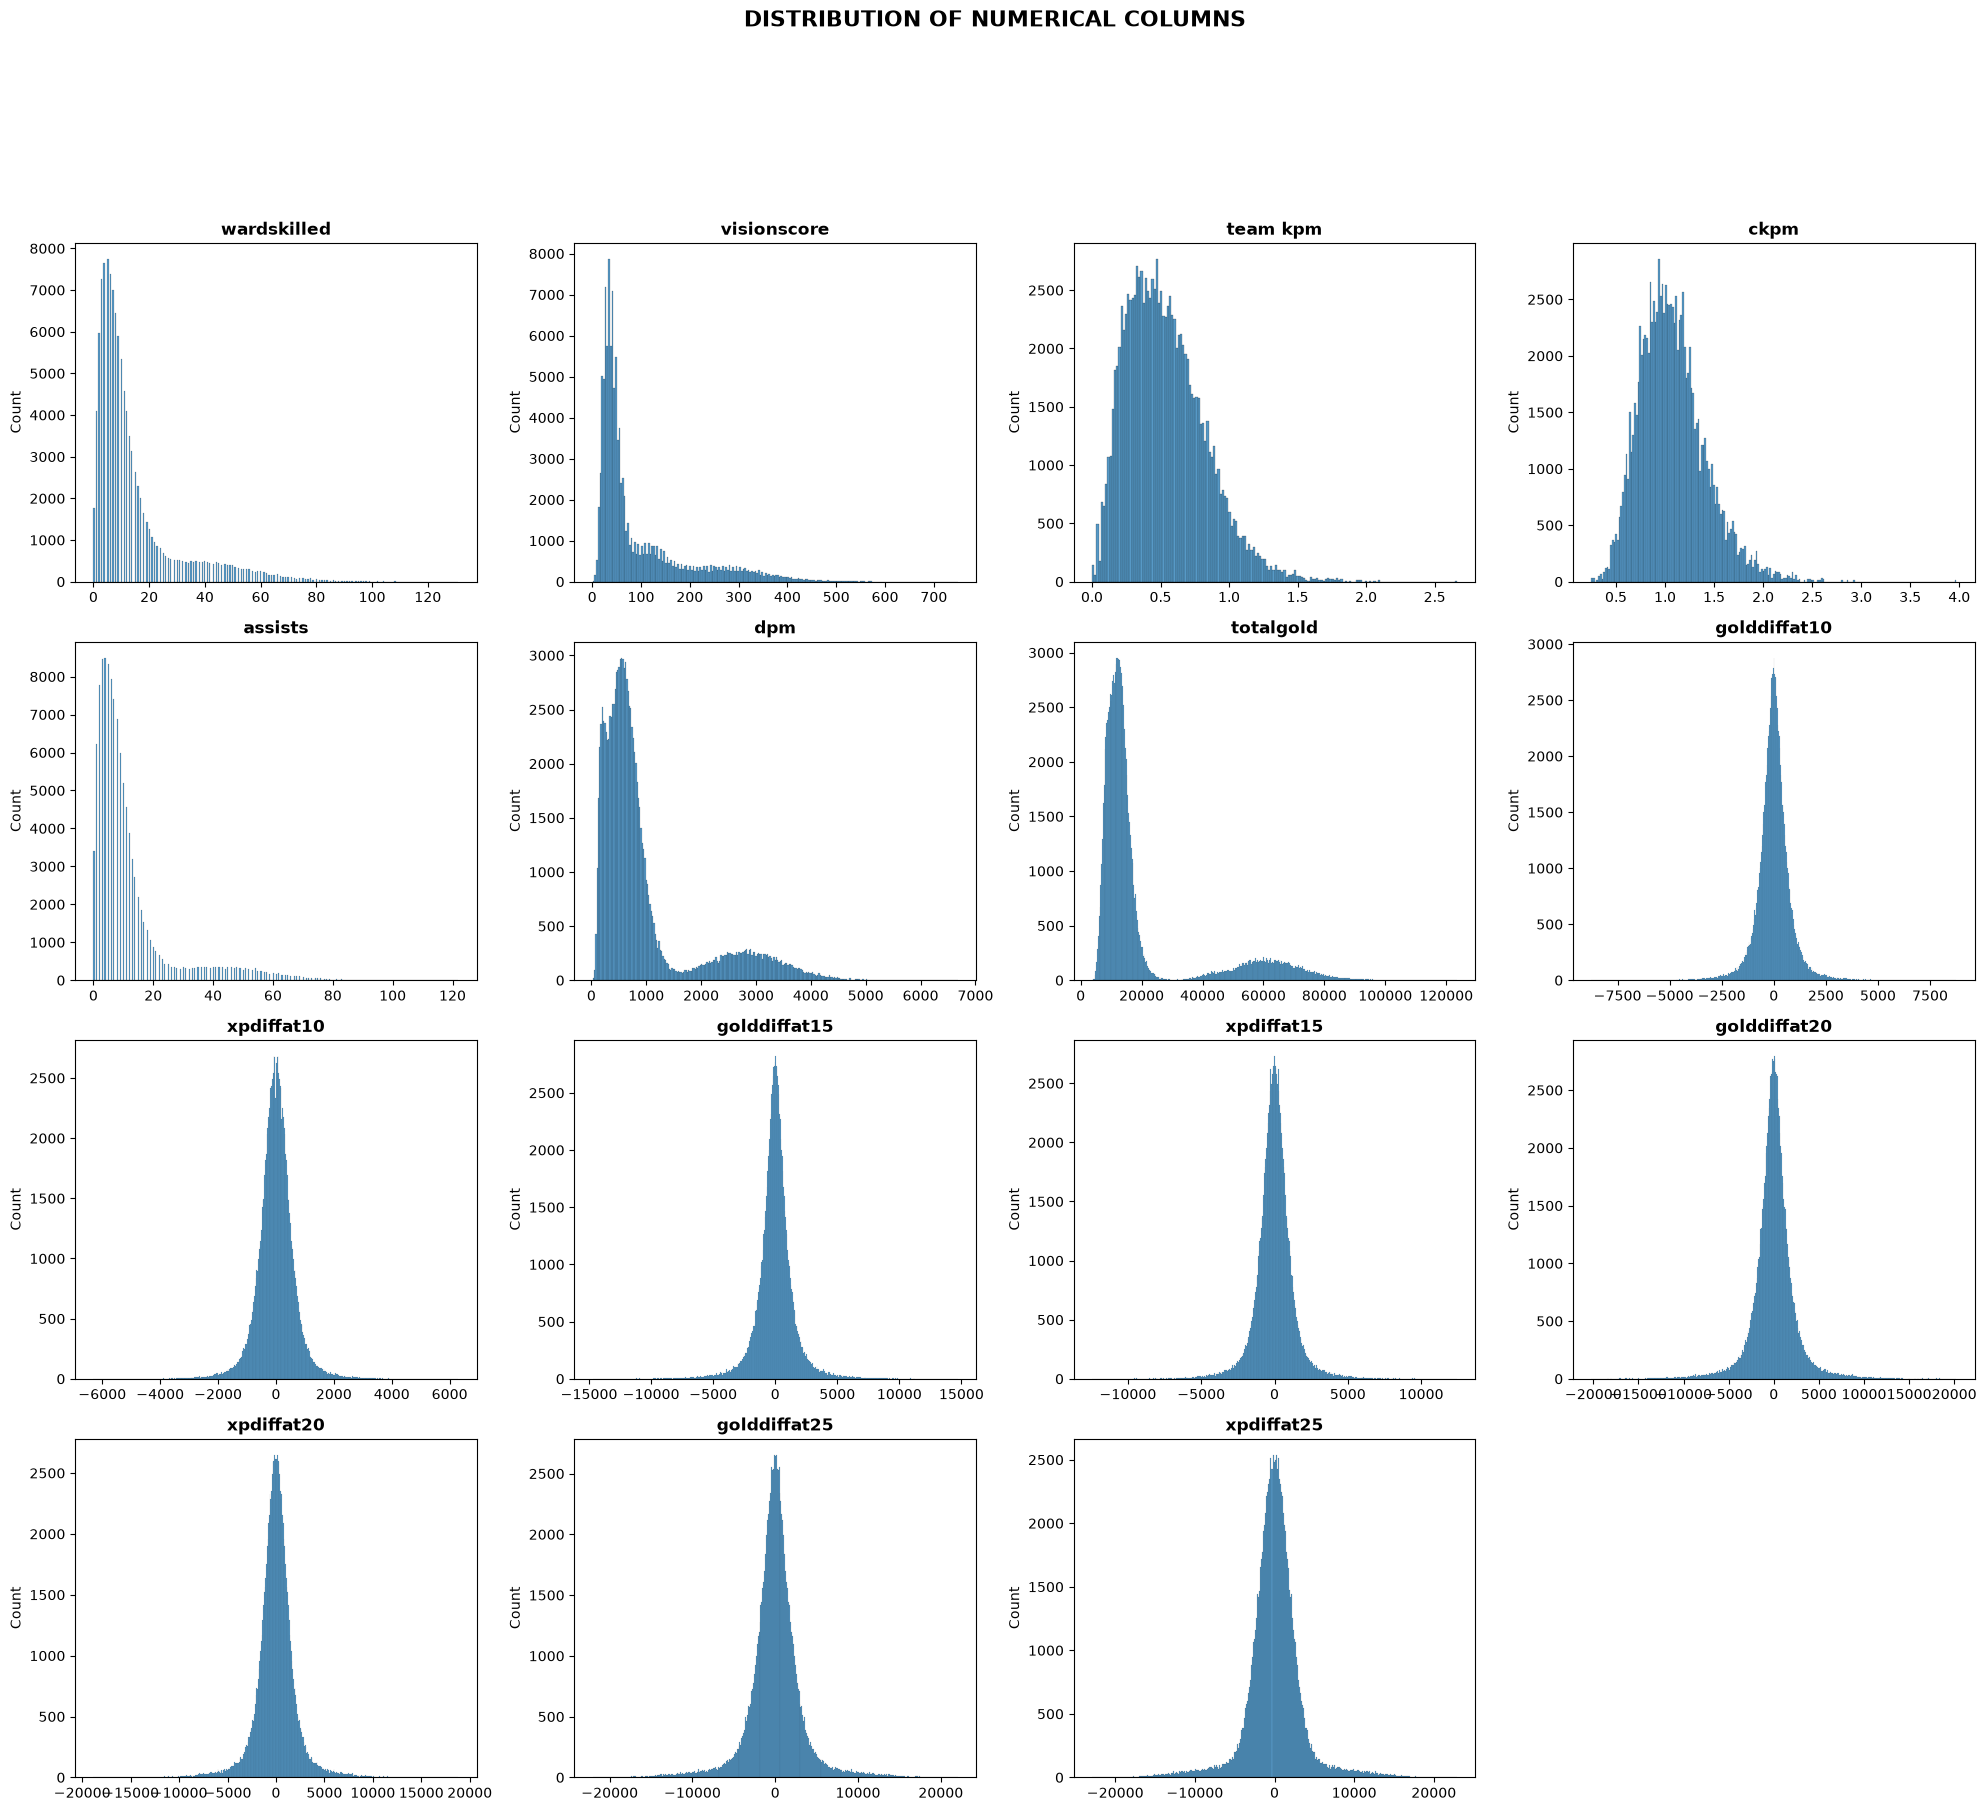

In [ ]:
visualize_num_distribution(df, drop_numbelow100, nrows=20, ncols=4, figsize=(20, 80))

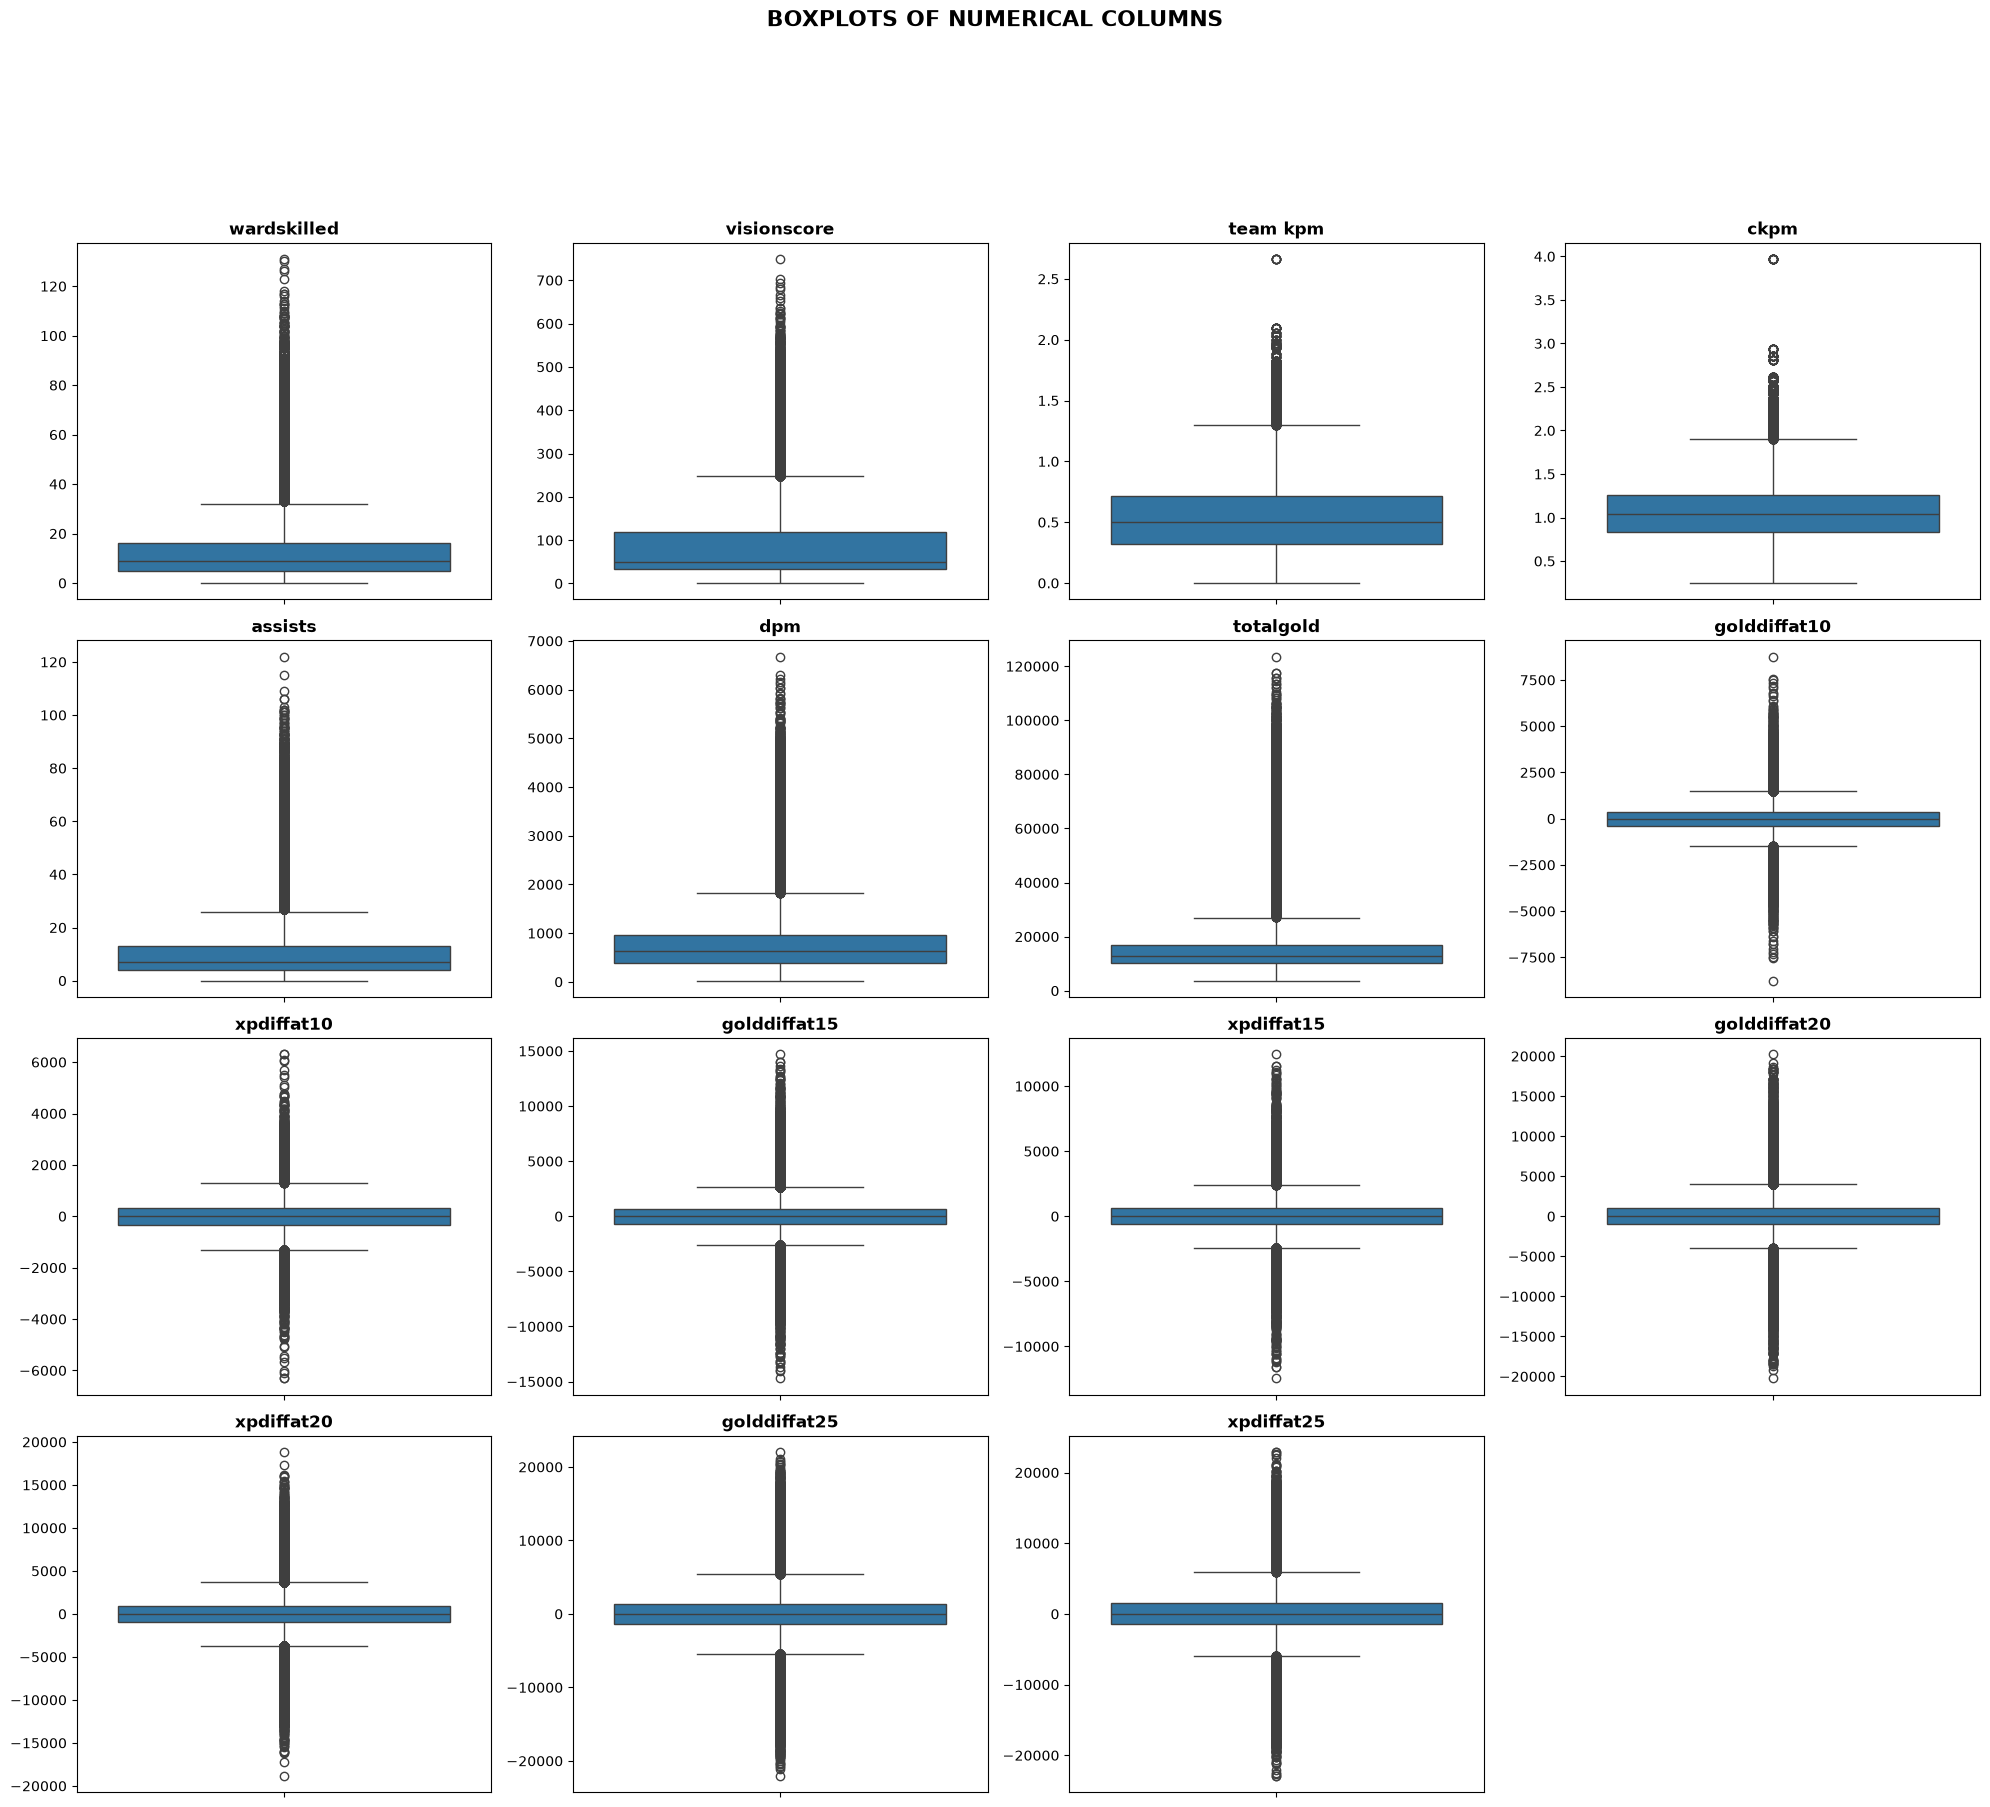

In [ ]:
visualize_outliers(df, drop_numbelow100, nrows=20, ncols=4, figsize=(20, 80))

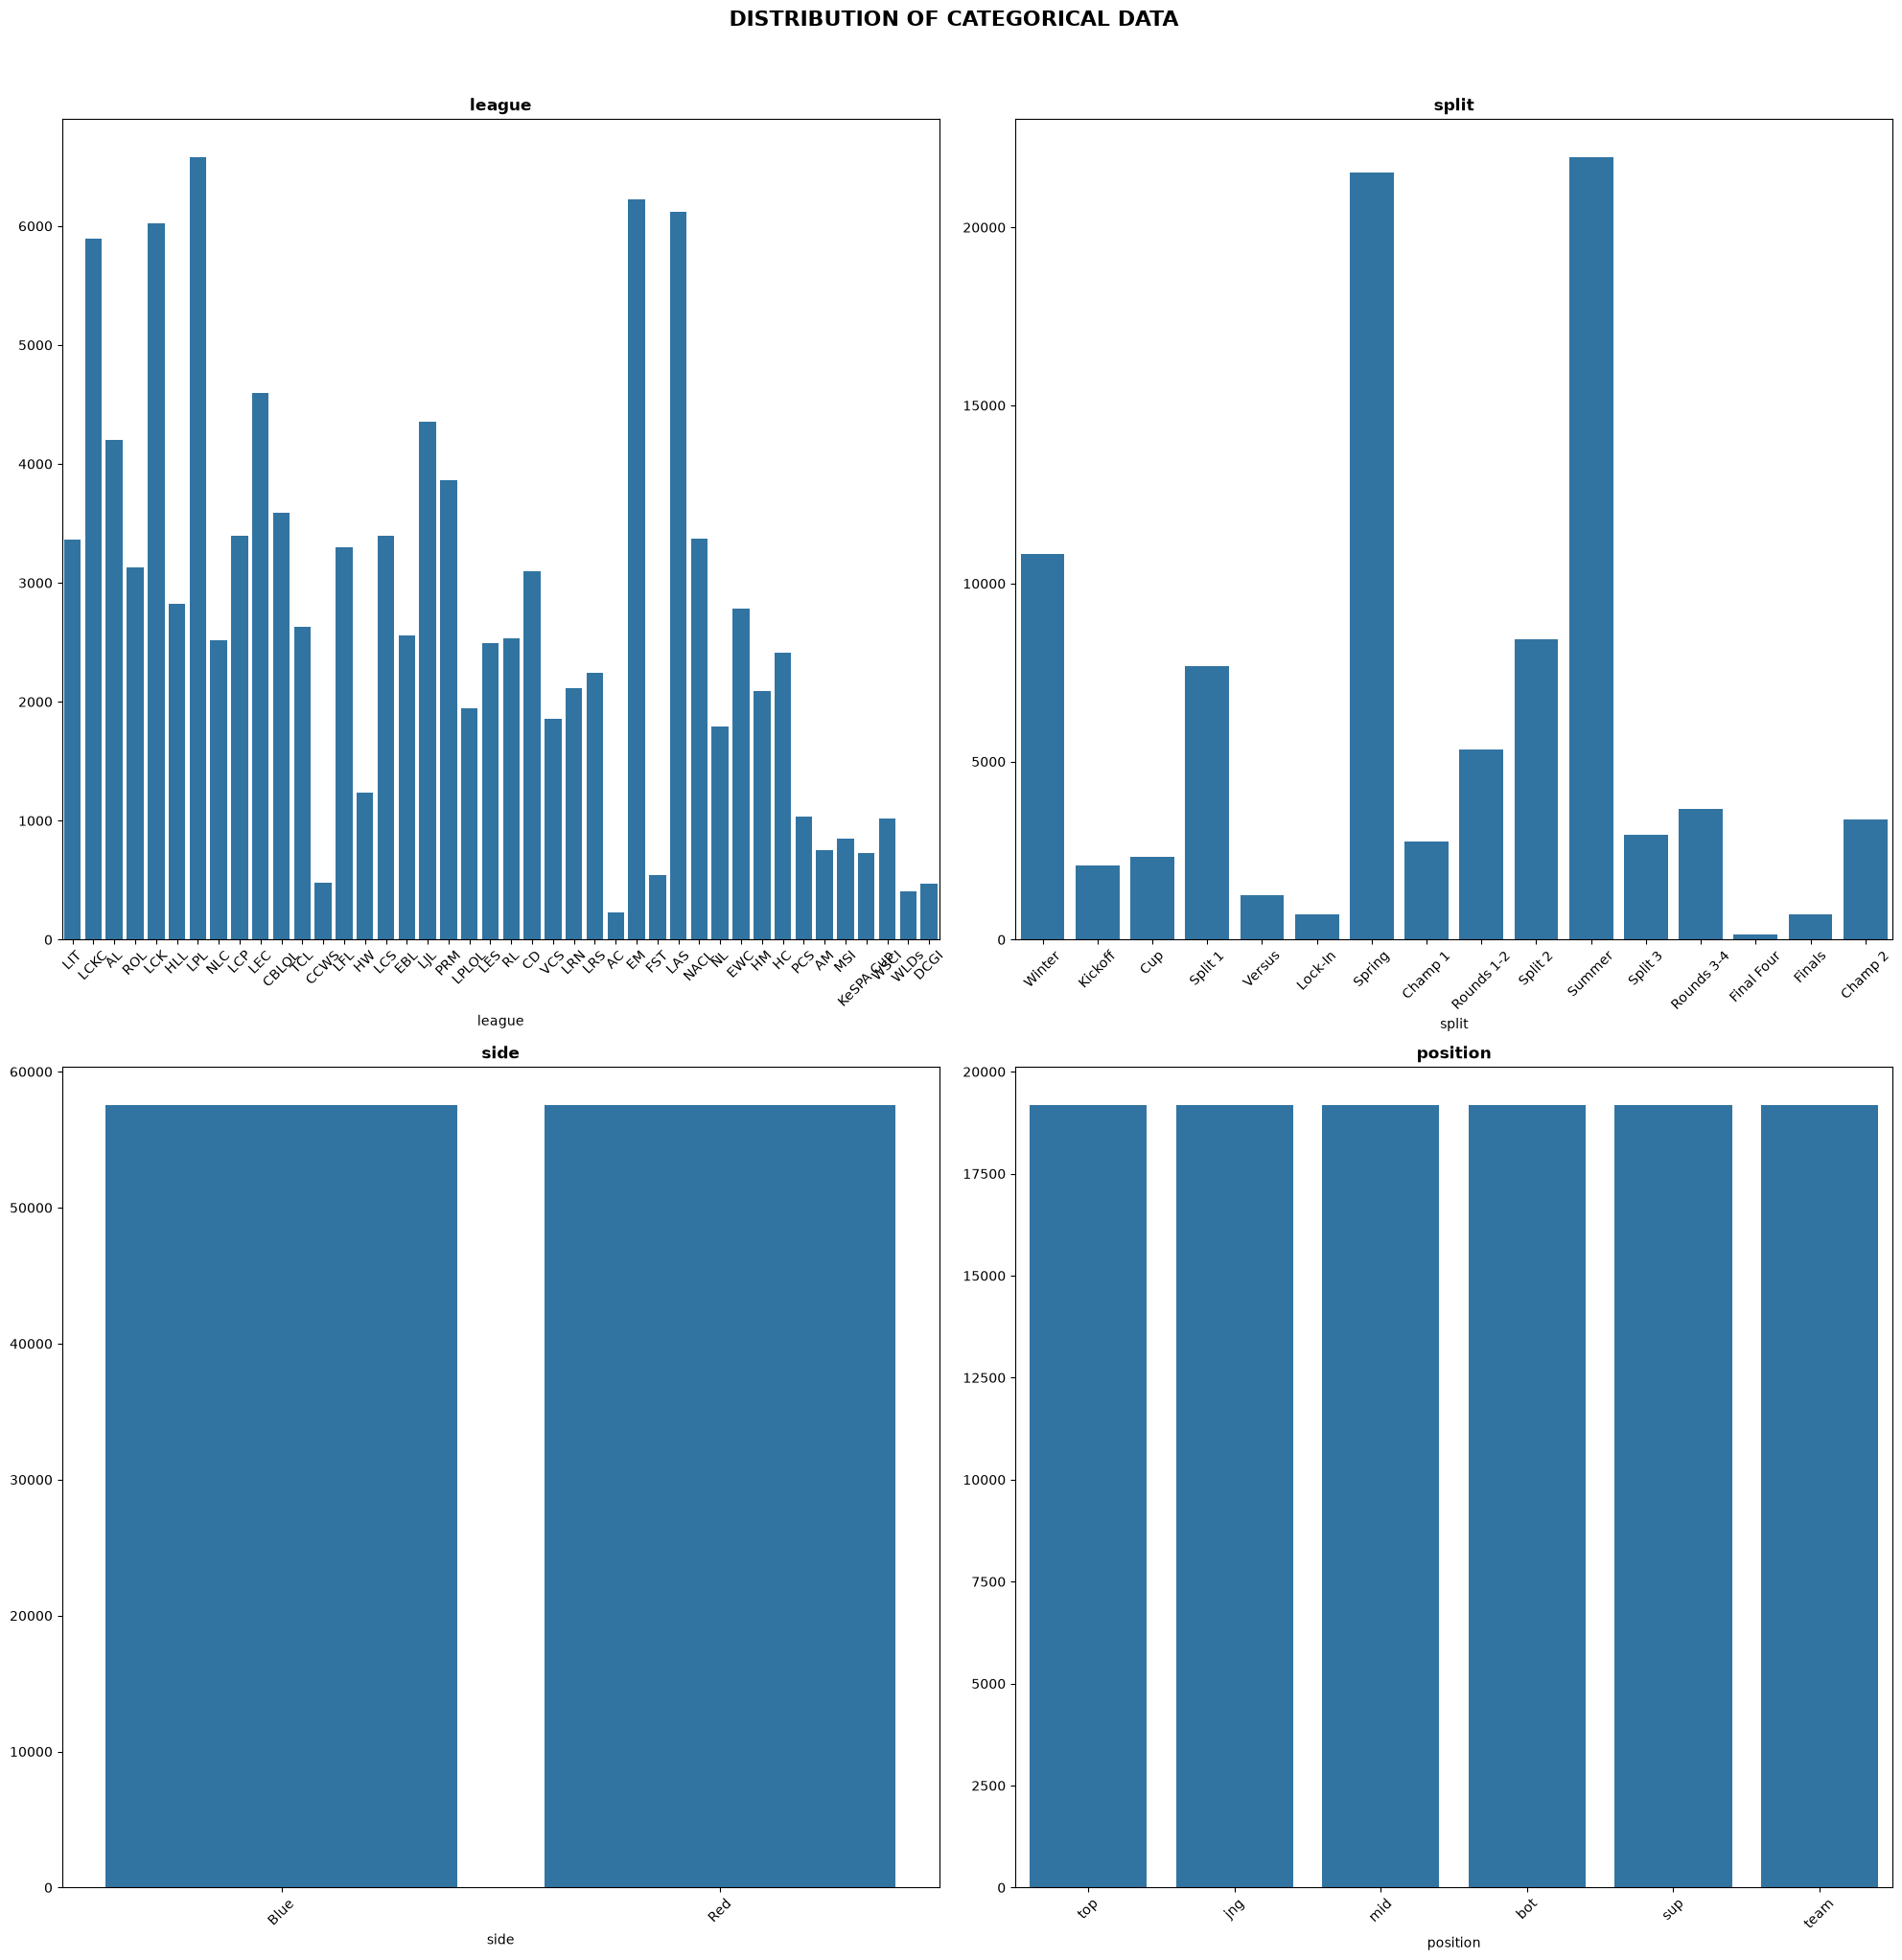

In [12]:
visualize_cat_distribution(df, catcols_to_drop, nrows=2, ncols=2)

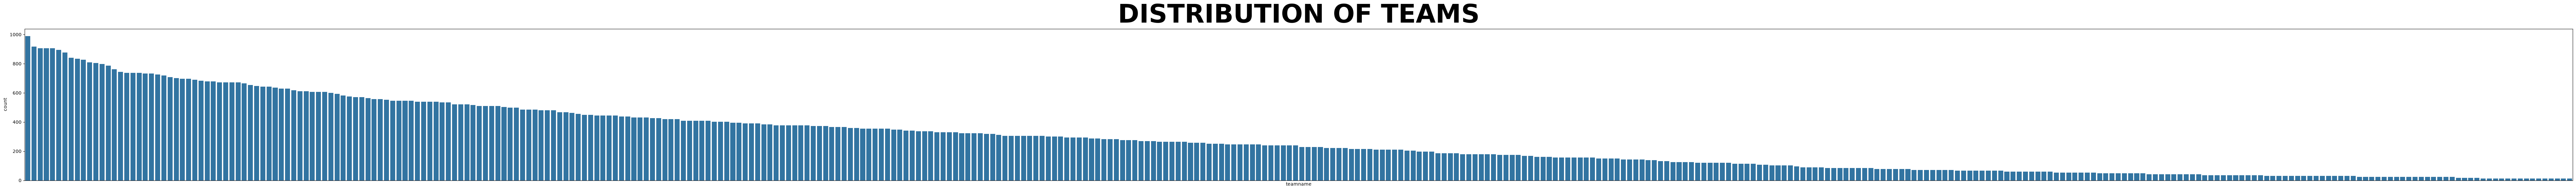

In [13]:
# Visualization for team names distribution
team_order = df["teamname"].value_counts().index
plt.figure(figsize=(100, 6))
sns.countplot(data=df, x='teamname', order=team_order)
plt.title('DISTRIBUTION OF TEAMS', fontsize=56, fontweight="bold")
plt.xticks([], [])
plt.show()

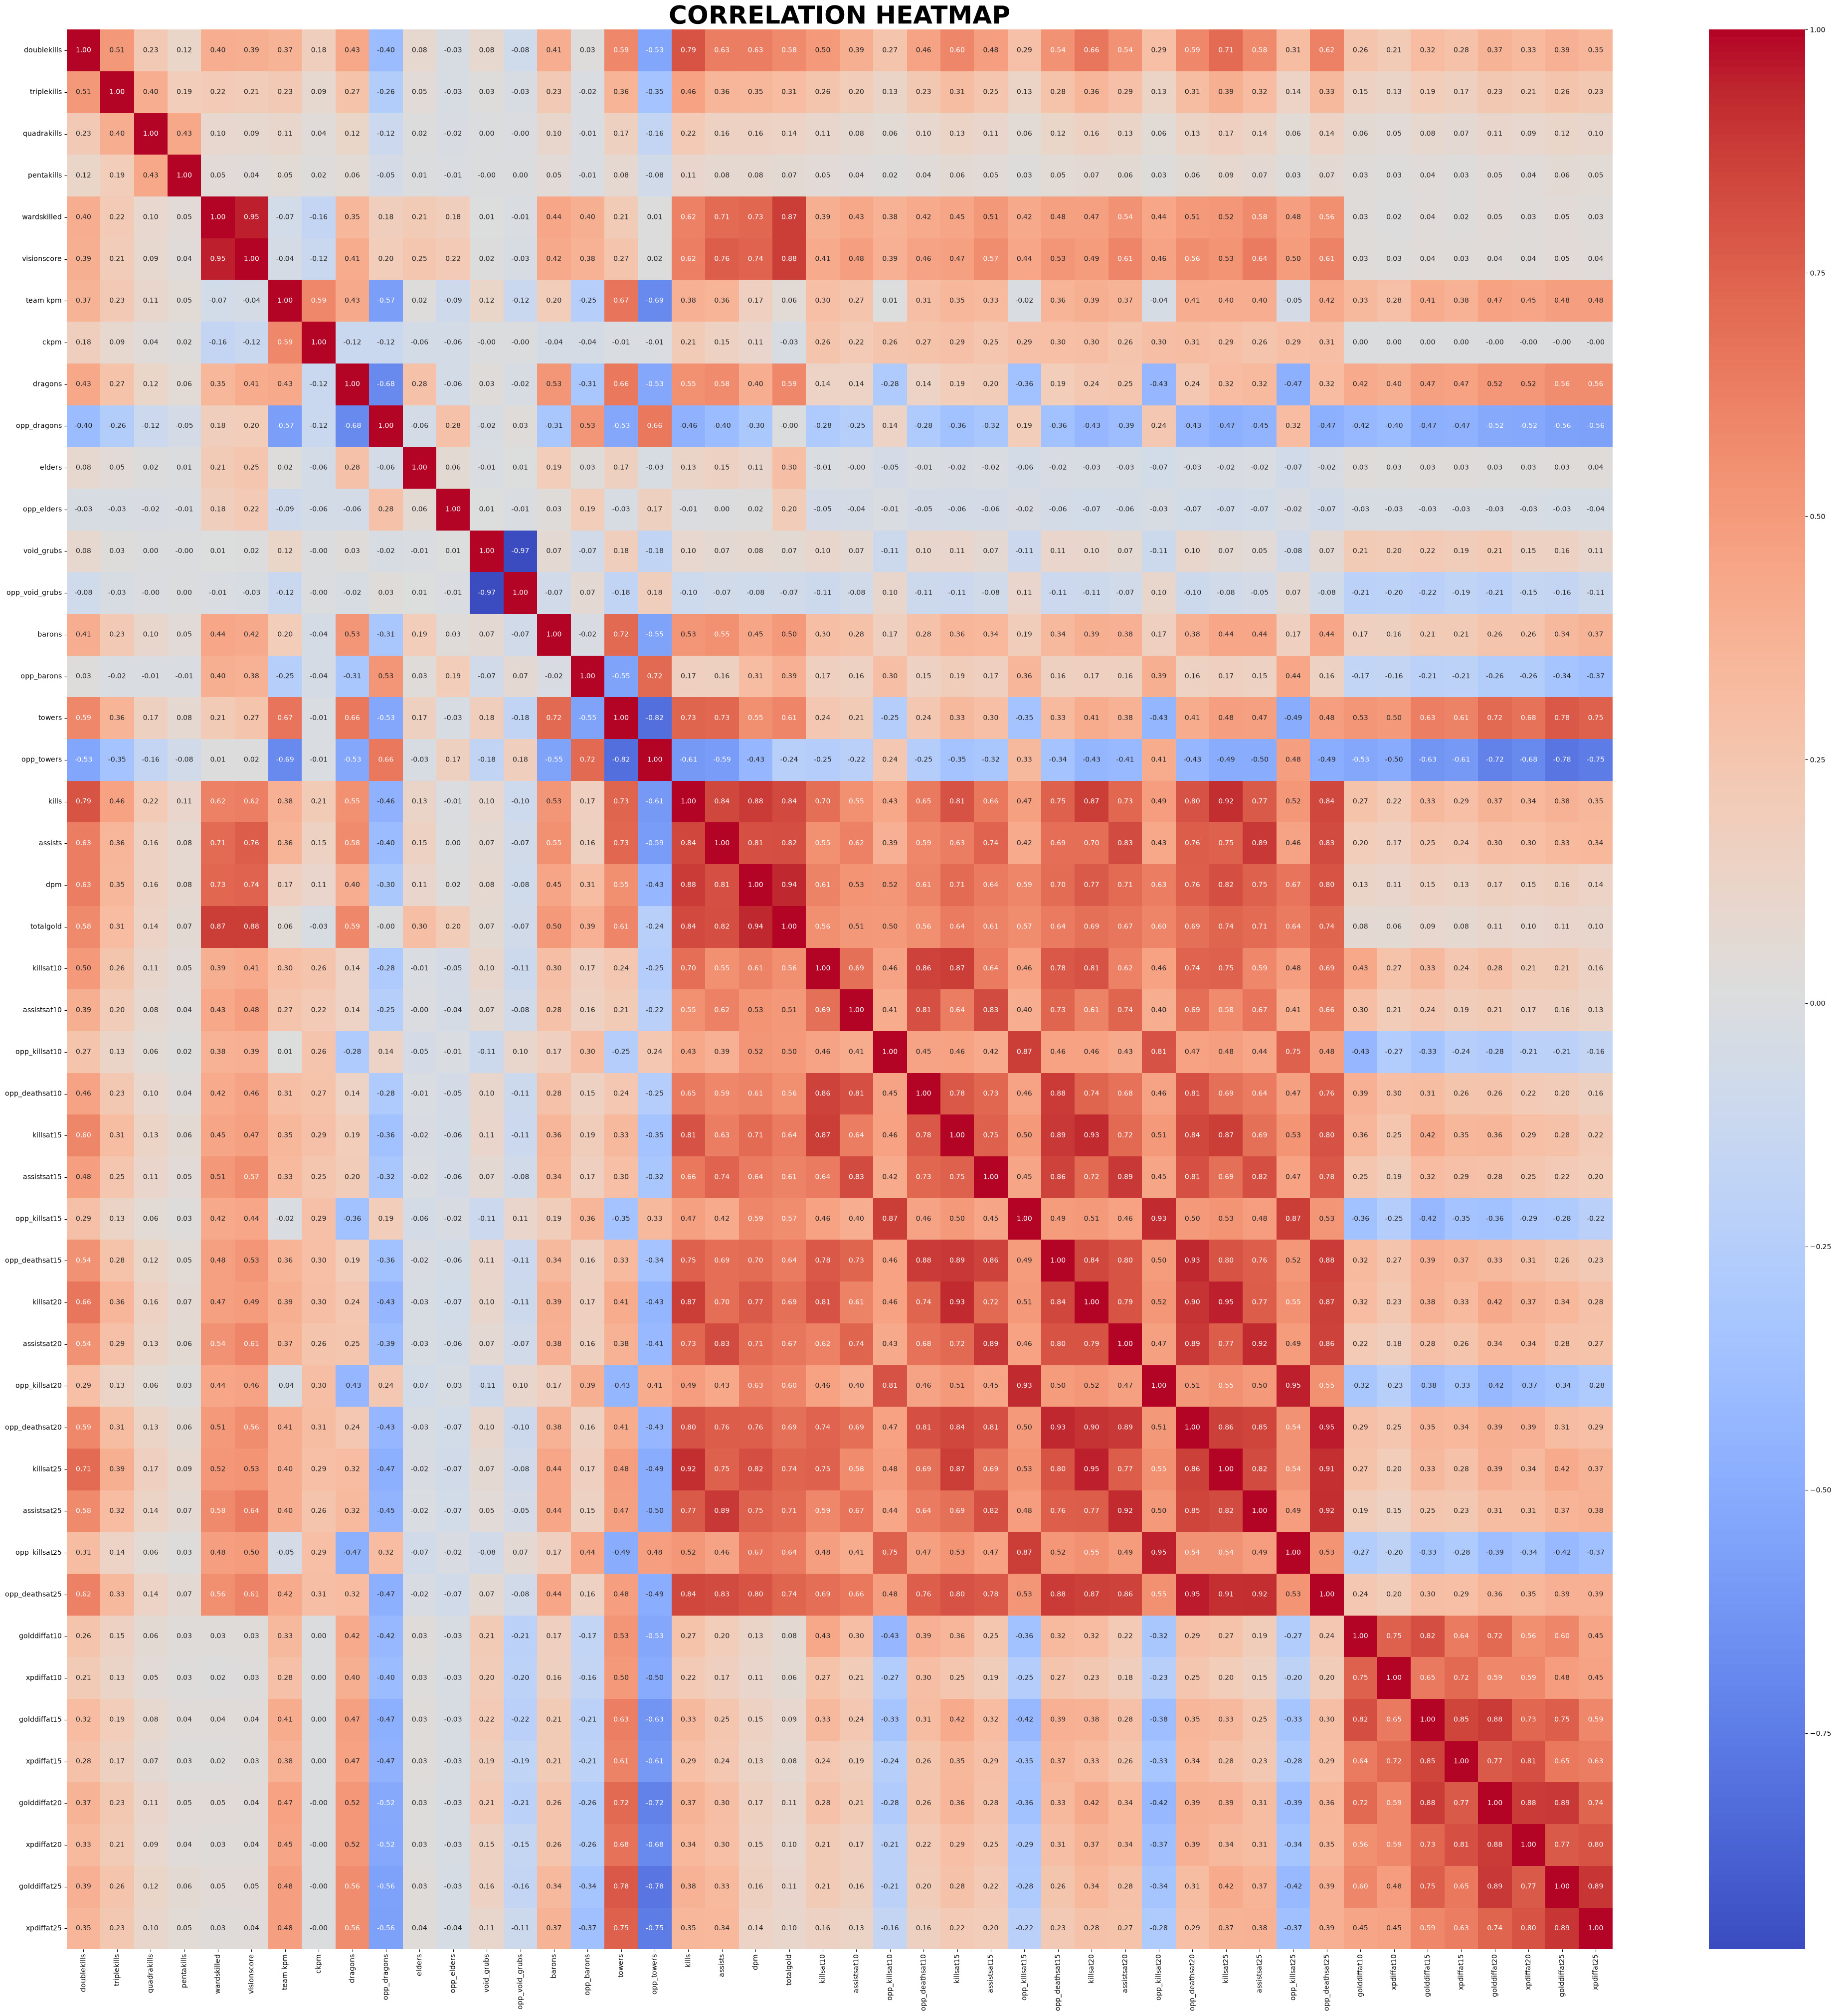

In [18]:
# Compute correlation matrix
co_mtx = df.drop(drop_numbelow3, axis='columns').corr(numeric_only=True)

# Plot correlation heatmap
plt.figure(figsize=(50, 50))
sns.heatmap(co_mtx, cmap='coolwarm', annot=True, fmt='.2f')
plt.title('CORRELATION HEATMAP', fontsize=36, fontweight="bold")
plt.show()